# Supplementary Figure S5: lineage-traced hematopoiesis

Recalculate the distribution errors and clone-fate agreement in S5c/d, then
draw the complete figure. Panels b–f use the same three LR-informed Full
models. The three No-interaction models were trained without the interaction
network using the corresponding training settings.

This walkthrough needs NumPy, pandas, SciPy and the figure dependencies.
It runs on a CPU from the per-simulation errors and clone probabilities
included with the repository. No finished image is used as a plotting input.
The final section shows how to repeat prediction with all six checkpoints.

In [1]:
from pathlib import Path
import os
import shutil
import tempfile
import pandas as pd
import CytoBridge as cb
from IPython.display import Image, display
from reproduction.nonspatial.weinreb_matched import summarize
from reproduction.nonspatial.update_weinreb_s4 import update

repo = Path(cb.__file__).resolve().parents[1]
source = repo / "reproduction/nonspatial/larry_evaluation"
output = Path(tempfile.mkdtemp(prefix="cytobridge-s4-"))
print(output)

/var/folders/b5/t2zljhrs6vq96hjn5_n9zzz80000gn/T/cytobridge-s4-cohkpqi6


## Recalculate the two comparisons

For S5c, each point represents one trained model, averaged over 50 prediction
runs. Bars show the mean across the three models. For S5d, each model was
used for ten predictions from the day-2 cells. We average clone-fate
probabilities across the three models before comparing them with the
observed descendants of 1,237 lineages. Averaging metric values instead
would answer a different question.

In [2]:
paths = summarize(source / "raw", output / "summary")
display(pd.read_csv(paths["clone_fate"])[["metric", "full", "no_interaction"]].round(3))
display(pd.read_csv(paths["distribution"])[["time", "w1_full", "w1_no_interaction", "w2_full", "w2_no_interaction"]].round(3))

,metric,full,no_interaction
0,tv_agreement,0.480,0.468
1,js_similarity,0.569,0.560
2,dominant_fate_match,0.476,0.473


,time,w1_full,w1_no_interaction,w2_full,w2_no_interaction
0,1.0,7.198,7.39,7.381,7.614
1,2.0,7.767,7.87,7.960,8.096


## Draw the complete S5

The unchanged panels use the measured coordinates, model-derived velocity
grids, interaction scores and pathway tables in the figure input bundle.
Replace its c/d tables with the values calculated above and draw all panels.

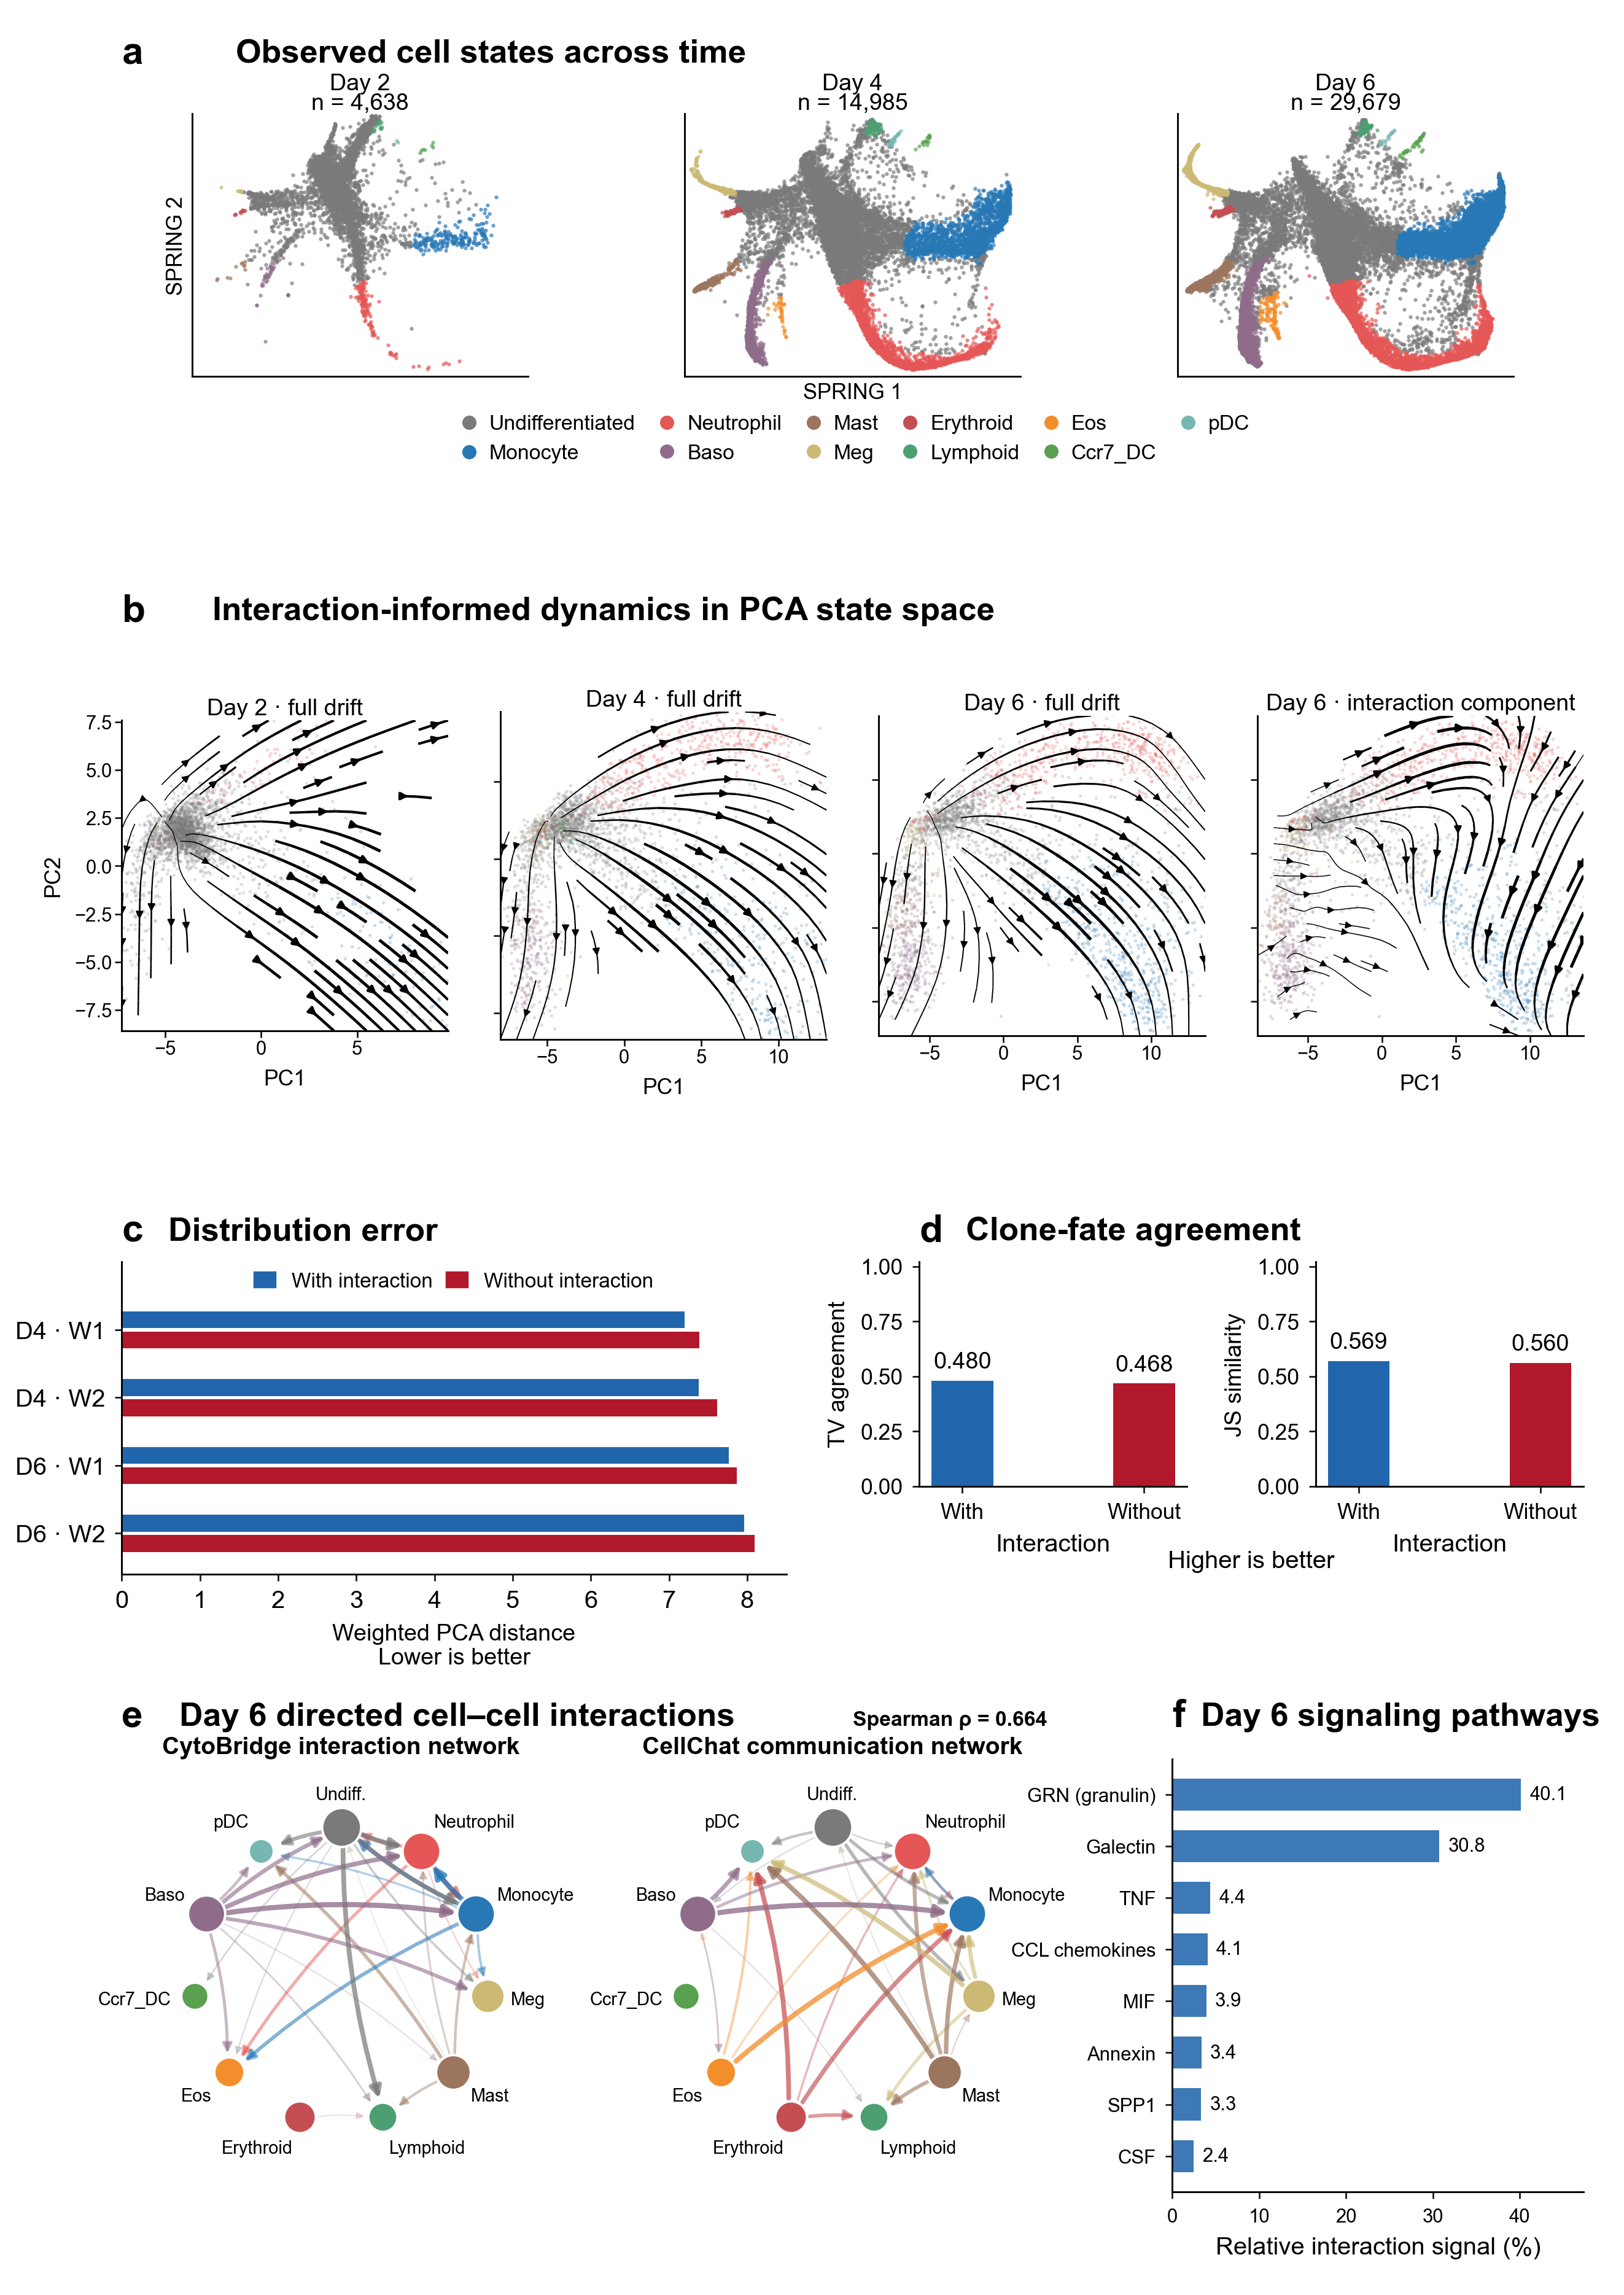

In [3]:
from reproduction.current_figures import draw_supplementary

bundle = output / "plot_inputs"
shutil.copytree(repo / "CytoBridge/results/data/nonspatial_figures", bundle)
update(output / "summary", bundle)
figures = draw_supplementary([5], output / "figures", results_dir=bundle)
display(Image(filename=str(figures["s5"][1]), width=720))

## Repeat prediction from the checkpoints

Download and extract `weinreb-s4-20261029.tar.gz` from
[the S5 archive](https://github.com/zhenyiizhang/cytobridge-spatial/releases/tag/weinreb-s4-20261029).
It includes the six checkpoints, prepared cells, per-run results, training
code and checksums. Access requires repository permission while it is private.

Set `CYTOBRIDGE_S4_ARCHIVE` to the extracted folder to run the optional cell
below on a GPU. It repeats both evaluations, averages the results in the
same order, and draws S5 from the newly calculated values. Otherwise the
cell leaves the CPU reconstruction above unchanged.

In [4]:
archive = os.environ.get("CYTOBRIDGE_S4_ARCHIVE")
if archive:
    from reproduction.nonspatial.weinreb_matched import evaluate
    evaluate(archive, output / "repeated", device=os.environ.get("CYTOBRIDGE_DEVICE", "cuda"))
    update(output / "repeated/summary", bundle)
    repeated = draw_supplementary([5], output / "repeated_figures", results_dir=bundle)
    display(Image(filename=str(repeated["s5"][1]), width=720))

### Check the averaging

Choose one day and distance measure in `distribution_means_per_training_seed.csv`.
The mean of its three Full values should equal the corresponding blue bar.
The same calculation applies to No-interaction. The full per-seed table also
shows the variation between independent training runs.

In [5]:
means = pd.read_csv(output / "summary/distribution_means_per_training_seed.csv")
means.query("time == 1 and metric == 'w2'").groupby("model").value.mean()

model
LR Full           7.381409
No-interaction    7.613639
Name: value, dtype: float64